# CDS 4003: Mobile Game In-App Purchases
## Stage 5: Model Selection and Development
**Models Implemented:** Decision Tree and XGBoost

This notebook compares two tree-based classifiers for `SpendingSegment` using a shared stratified holdout set. All reported test metrics are recalculated when the notebook is run.

## Model 1: Decision Tree Classifier

A Decision Tree creates a sequence of feature-based splits and is included as an interpretable model. Gini and Entropy are compared as preliminary un-tuned settings; GridSearchCV then selects tree depth and leaf size using training folds only. Macro-F1 is used for model selection because it gives each spending segment equal weight.

The predictor list is explicit. It uses baseline profile and session variables, and excludes identifiers, direct spending fields, EDA helper variables, and simulated 30-day fields that may encode the target-generation assumptions. The models therefore assess a narrower, more defensible predictor set. As the source data are generated, results still require cautious interpretation and do not establish performance on live players.

Rows used: 247,500
Predictors: ['Age', 'Country', 'Device', 'GameGenre', 'SessionCount', 'AverageSessionLength']
Target distribution:
SpendingSegment
Minnow     208328
Dolphin     33670
Whale        5502
Name: count, dtype: int64
Decision Tree — Gini (untuned)
                      0.946202
                      0.862316
                      0.866511

Classification report:
              precision    recall  f1-score   support

      Minnow     0.9674    0.9707    0.9690     41666
     Dolphin     0.8345    0.8190    0.8267      6734
       Whale     0.8105    0.7973    0.8038      1100

    accuracy                         0.9462     49500
   macro avg     0.8708    0.8623    0.8665     49500
weighted avg     0.9458    0.9462    0.9460     49500



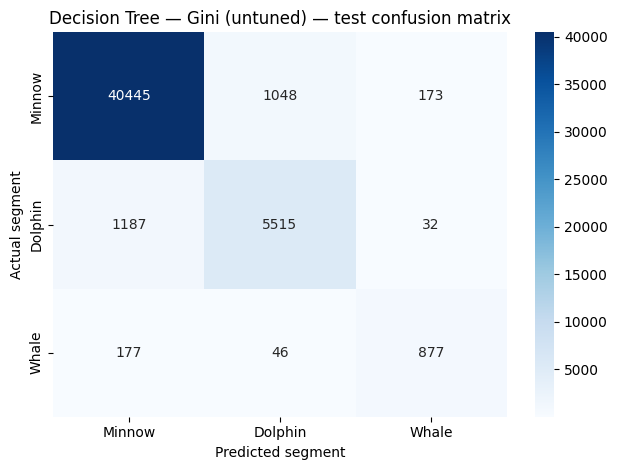

Decision Tree — Entropy (untuned)
                         0.942889
                         0.858477
                         0.860312

Classification report:
              precision    recall  f1-score   support

      Minnow     0.9667    0.9670    0.9669     41666
     Dolphin     0.8181    0.8184    0.8183      6734
       Whale     0.8017    0.7900    0.7958      1100

    accuracy                         0.9429     49500
   macro avg     0.8622    0.8585    0.8603     49500
weighted avg     0.9428    0.9429    0.9429     49500



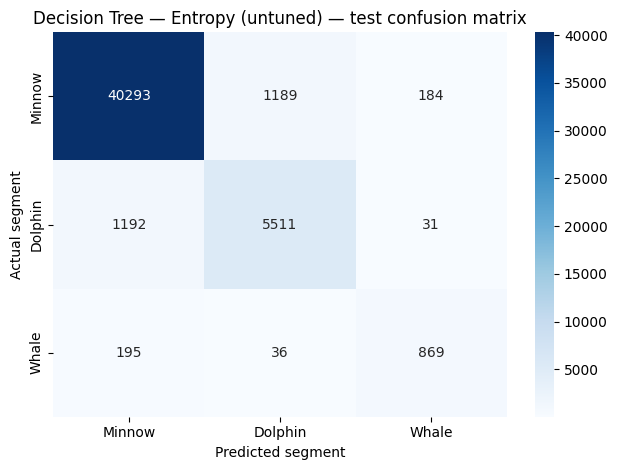

Best Decision Tree parameters: {'model__criterion': 'gini', 'model__max_depth': 15, 'model__min_samples_leaf': 10}
Best cross-validation Macro-F1: 0.4046
Decision Tree — tuned
              0.58604
             0.656828
             0.424868

Classification report:
              precision    recall  f1-score   support

      Minnow     0.9304    0.5930    0.7243     41666
     Dolphin     0.3650    0.4948    0.4201      6734
       Whale     0.0703    0.8827    0.1302      1100

    accuracy                         0.5860     49500
   macro avg     0.4552    0.6568    0.4249     49500
weighted avg     0.8343    0.5860    0.6697     49500



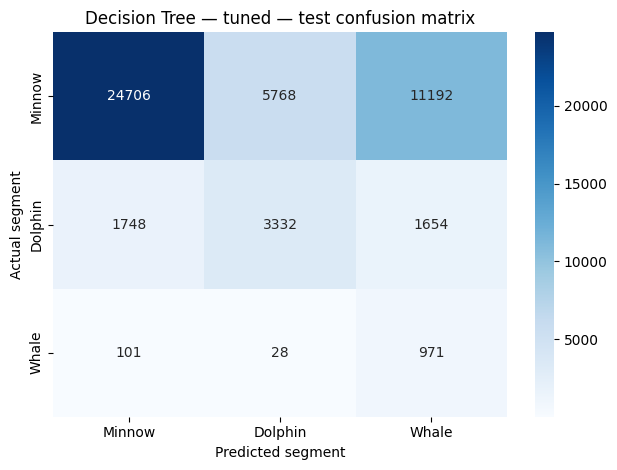

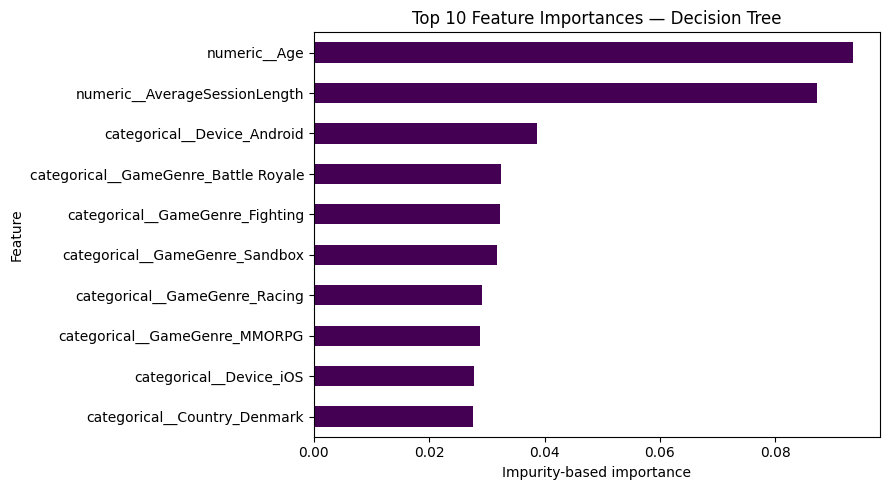

In [1]:
# 1. Import the libraries used for data preparation, modeling, evaluation, and plots
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix
)

# 2. Set reproducibility values and identify the dataset, target, labels, and predictors
RANDOM_STATE = 42
DATA_PATH = "mobile_game_players_eda_features.csv"
TARGET = "SpendingSegment"
LABELS = ["Minnow", "Dolphin", "Whale"]
FEATURE_COLS = ["Age", "Country", "Device", "GameGenre", "SessionCount", "AverageSessionLength"]

# Keep predictors explicit so derived or simulated helper fields cannot enter silently.
# 3. Load the prepared dataset and retain only the approved predictor columns
df = pd.read_csv(DATA_PATH).drop_duplicates().copy()
missing_columns = [c for c in FEATURE_COLS + [TARGET] if c not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")
df = df.dropna(subset=[TARGET]).loc[lambda data: data[TARGET].isin(LABELS)].copy()
X = df[FEATURE_COLS].copy()
y = df[TARGET].copy()

# 4. Split the data into stratified training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# 5. Build preprocessing so imputation and one-hot encoding are fitted within each training fold
categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_cols),
        ("categorical", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_cols),
    ],
    remainder="drop",
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

print(f"Rows used: {len(df):,}")
print("Predictors:", FEATURE_COLS)
print("Target distribution:")
print(y.value_counts().reindex(LABELS))

# Use one evaluator so all candidate models and the baseline report comparable metrics.
# 6. Define one evaluation function for consistent metrics, class reports, and confusion matrices
def evaluate_model(name, y_true, predictions, make_plot=True):
    scores = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_true, predictions),
        "Macro-F1": f1_score(y_true, predictions, average="macro"),
    }
    print(pd.Series(scores).to_string(index=False))
    print("\nClassification report:")
    print(classification_report(y_true, predictions, labels=LABELS, digits=4, zero_division=0))
    if make_plot:
        cm = confusion_matrix(y_true, predictions, labels=LABELS)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
        plt.title(f"{name} — test confusion matrix")
        plt.xlabel("Predicted segment")
        plt.ylabel("Actual segment")
        plt.tight_layout()
        plt.show()
    return scores

# 7. Fit preliminary Gini and Entropy trees on the same split for a like-for-like comparison.
gini_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(criterion="gini", class_weight="balanced", random_state=RANDOM_STATE)),
])
entropy_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(criterion="entropy", class_weight="balanced", random_state=RANDOM_STATE)),
])
gini_pipeline.fit(X_train, y_train)
entropy_pipeline.fit(X_train, y_train)
gini_scores = evaluate_model("Decision Tree — Gini (untuned)", y_test, gini_pipeline.predict(X_test))
entropy_scores = evaluate_model("Decision Tree — Entropy (untuned)", y_test, entropy_pipeline.predict(X_test))

# 8. Tune Decision Tree settings using 3-fold cross-validation and Macro-F1
param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [5, 10, 15],
    "model__min_samples_leaf": [10, 50, 100],
}
dt_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
])
dt_search = GridSearchCV(dt_pipeline, param_grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True)
dt_search.fit(X_train, y_train)
best_dt = dt_search.best_estimator_
print("Best Decision Tree parameters:", dt_search.best_params_)
print("Best cross-validation Macro-F1:", round(dt_search.best_score_, 4))
y_pred_dt = best_dt.predict(X_test)
dt_scores = evaluate_model("Decision Tree — tuned", y_test, y_pred_dt)

# 9. Plot the tuned Decision Tree feature importance (descriptive, not causal).
feature_names = best_dt.named_steps["preprocess"].get_feature_names_out()
importance = pd.Series(best_dt.named_steps["model"].feature_importances_, index=feature_names).sort_values(ascending=False).head(10)
ax = importance.sort_values().plot.barh(figsize=(9, 5), colormap="viridis")
ax.set_title("Top 10 Feature Importances — Decision Tree")
ax.set_xlabel("Impurity-based importance")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

## Decision Tree Results & Insights

Use the recalculated test-set metrics and class-level report above when writing the results. Macro-F1 and Balanced Accuracy are more informative than accuracy alone for this imbalanced target. Whale and Dolphin recall should be read together with their precision: high recall can still involve many false positives. Feature importance is not evidence that a variable causes spending.

## Model 2: XGBoost Classifier

XGBoost builds trees sequentially, with each step improving errors made earlier in the ensemble. It is suitable for structured data with non-linear relationships. The same predictor set, split, preprocessing, and Macro-F1 objective are used to make the comparison consistent. Balanced sample weights are computed from the training labels. The encoder and imputer are fitted inside each cross-validation training fold through the pipeline.

XGBoost — untuned reference
                   0.709293
                   0.806147
                   0.536273

Classification report:
              precision    recall  f1-score   support

      Minnow     0.9653    0.6933    0.8070     41666
     Dolphin     0.3886    0.7679    0.5160      6734
       Whale     0.1680    0.9573    0.2858      1100

    accuracy                         0.7093     49500
   macro avg     0.5073    0.8061    0.5363     49500
weighted avg     0.8691    0.7093    0.7558     49500



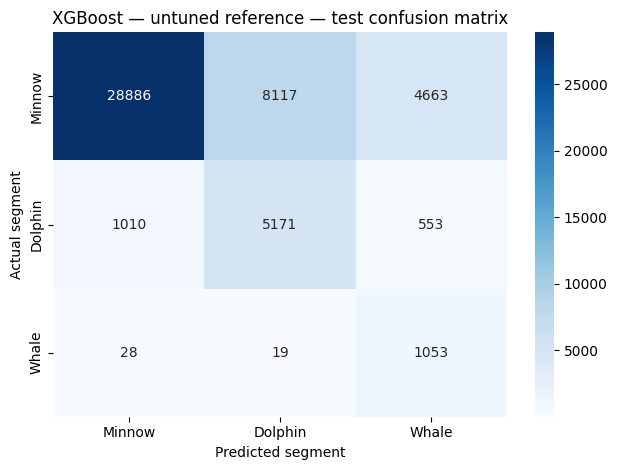

Best XGBoost parameters: {'model__max_depth': 7, 'model__n_estimators': 100}
Best cross-validation Macro-F1: 0.7807
XGBoost — tuned
       0.881455
       0.918827
       0.765134

Classification report:
              precision    recall  f1-score   support

      Minnow     0.9894    0.8712    0.9266     41666
     Dolphin     0.5889    0.9335    0.7222      6734
       Whale     0.4897    0.9518    0.6467      1100

    accuracy                         0.8815     49500
   macro avg     0.6893    0.9188    0.7651     49500
weighted avg     0.9238    0.8815    0.8925     49500



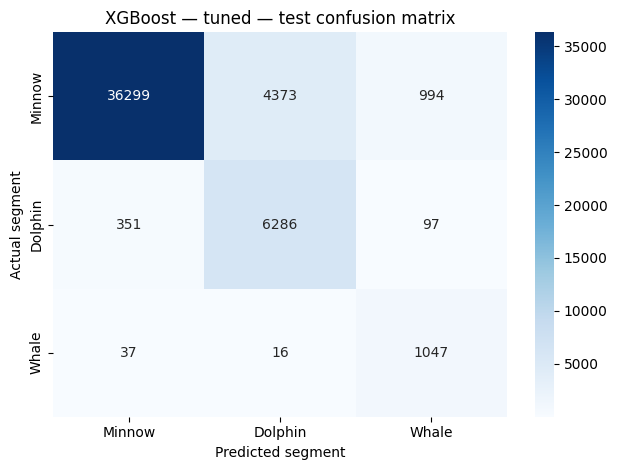

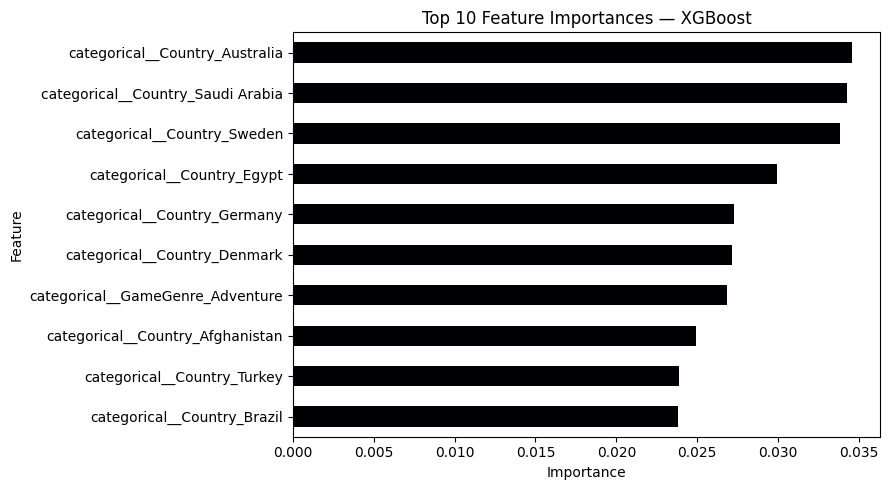

In [2]:
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

# 1. Convert the class labels to integer codes required by XGBoost
label_to_int = {label: i for i, label in enumerate(LABELS)}
int_to_label = {i: label for label, i in label_to_int.items()}
y_train_int = y_train.map(label_to_int)
y_test_int = y_test.map(label_to_int)

# 2. Fit an untuned XGBoost reference model for comparison before tuning.
xgb_reference = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", XGBClassifier(
        objective="multi:softprob", num_class=len(LABELS), eval_metric="mlogloss",
        tree_method="hist", max_depth=5, n_estimators=50,
        random_state=RANDOM_STATE, n_jobs=1,
    )),
])
reference_weights = compute_sample_weight(class_weight="balanced", y=y_train_int)
xgb_reference.fit(X_train, y_train_int, model__sample_weight=reference_weights)
reference_pred_int = xgb_reference.predict(X_test).astype(int)
reference_pred = pd.Series(reference_pred_int).map(int_to_label).to_numpy()
xgb_reference_scores = evaluate_model("XGBoost — untuned reference", y_test, reference_pred)

# 3. Define the XGBoost pipeline; preprocessing remains inside cross-validation.
xgb_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", XGBClassifier(
        objective="multi:softprob", num_class=len(LABELS), eval_metric="mlogloss",
        tree_method="hist", random_state=RANDOM_STATE, n_jobs=1,
    )),
])
# 4. Tune tree depth and number of estimators using 3-fold CV Macro-F1
xgb_params = {
    "model__max_depth": [3, 5, 7],
    "model__n_estimators": [50, 100],
}
xgb_weights = compute_sample_weight(class_weight="balanced", y=y_train_int)
xgb_search = GridSearchCV(xgb_pipeline, xgb_params, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True)
xgb_search.fit(X_train, y_train_int, model__sample_weight=xgb_weights)
best_xgb = xgb_search.best_estimator_
print("Best XGBoost parameters:", xgb_search.best_params_)
print("Best cross-validation Macro-F1:", round(xgb_search.best_score_, 4))
xgb_pred_int = best_xgb.predict(X_test).astype(int)
y_pred_xgb = pd.Series(xgb_pred_int).map(int_to_label).to_numpy()
xgb_scores = evaluate_model("XGBoost — tuned", y_test, y_pred_xgb)

# 5. Plot the tuned XGBoost feature importance (descriptive, not causal).
xgb_names = best_xgb.named_steps["preprocess"].get_feature_names_out()
xgb_importance = pd.Series(best_xgb.named_steps["model"].feature_importances_, index=xgb_names).sort_values(ascending=False).head(10)
ax = xgb_importance.sort_values().plot.barh(figsize=(9, 5), colormap="magma")
ax.set_title("Top 10 Feature Importances — XGBoost")
ax.set_xlabel("Importance")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

## XGBoost Results & Insights

Use the recalculated held-out metrics and the class-level report to compare XGBoost with the Decision Tree. A higher Whale recall is useful for identifying more high-spending players, but its practical value depends on the corresponding precision and the cost of unnecessary offers. Classification performance does not by itself demonstrate campaign effectiveness or increased revenue.

## Baseline Comparison (Dummy Classifier)

A majority-class Dummy model provides a reference point for interpreting accuracy under class imbalance. It uses the same training and test records as the other models.

Dummy — majority class
              0.841737
              0.333333
               0.30469

Classification report:
              precision    recall  f1-score   support

      Minnow     0.8417    1.0000    0.9141     41666
     Dolphin     0.0000    0.0000    0.0000      6734
       Whale     0.0000    0.0000    0.0000      1100

    accuracy                         0.8417     49500
   macro avg     0.2806    0.3333    0.3047     49500
weighted avg     0.7085    0.8417    0.7694     49500



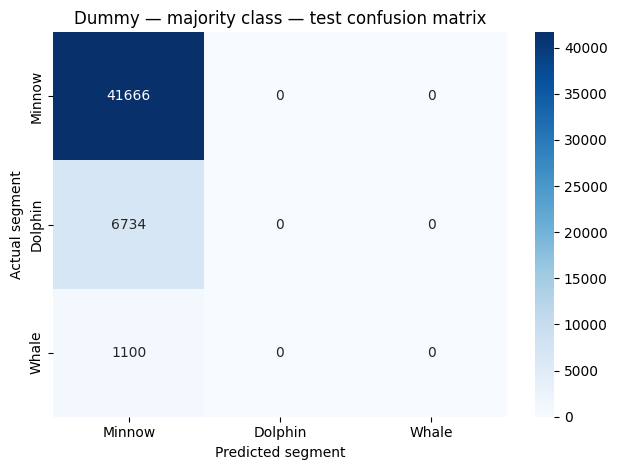


Held-out test comparison:
                                   Accuracy  Balanced Accuracy  Macro-F1
Model                                                                   
Dummy — majority class               0.8417             0.3333    0.3047
Decision Tree — Gini (untuned)       0.9462             0.8623    0.8665
Decision Tree — Entropy (untuned)    0.9429             0.8585    0.8603
Decision Tree — tuned                0.5860             0.6568    0.4249
XGBoost — untuned reference          0.7093             0.8061    0.5363
XGBoost — tuned                      0.8815             0.9188    0.7651


In [3]:
# 1. Fit a majority-class Dummy model as a simple baseline
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)
dummy_scores = evaluate_model("Dummy — majority class", y_test, y_pred_dummy)

# 2. Compare held-out test metrics for the baseline and each tree model
comparison = pd.DataFrame([
    dummy_scores, gini_scores, entropy_scores, dt_scores,
    xgb_reference_scores, xgb_scores,
]).set_index("Model")
print("\nHeld-out test comparison:")
print(comparison.round(4).to_string())